In [1]:
import os
import re
import time
import enum


import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import git


import torch
from torch import nn
from torch.optim import Adam
from torchvision import transforms, datasets
from torchvision.utils import make_grid, save_image
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter

In [2]:
BINARIES_PATH = os.path.join(os.getcwd(), 'models', 'binaries') # Path to the folder: current_directory/models/binaries
CHECKPOINTS_PATH = os.path.join(os.getcwd(), 'models', 'checkpoints')  # Path to the folder: current_directory/models/checkpoints

DATA_DIR_PATH = os.path.join(os.getcwd(), 'data')  # Path to the folder: current_directory/data
DEBUG_IMAGERY_PATH = os.path.join(DATA_DIR_PATH, 'debug_imagery')  # Path to the folder: current_directory/data/debug_imagery

MNIST_IMG_SIZE = 28 # Size of images (28×28) in the MNIST dataset

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.56MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 129kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.22MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.49MB/s]


Dataset size: 60000 images.
Image shape torch.Size([1, 28, 28])


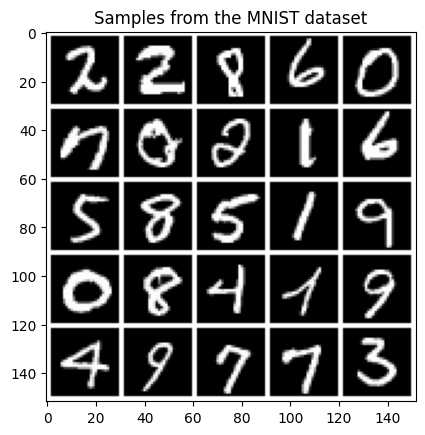

In [3]:
batch_size = 128 # Number of images processed in one training batch



transform = transforms.Compose([
        transforms.ToTensor(), # Converts image to PyTorch tensor
        transforms.Normalize((.5,), (.5,)) # Normalizes pixel values to range [-1, 1]
    ])


mnist_dataset = datasets.MNIST(root=DATA_DIR_PATH, train=True, download=True, transform=transform)
# Loads the MNIST dataset from the data folder and applies the transform

mnist_data_loader = DataLoader(mnist_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
# Creates a DataLoader to load data in batches and shuffle it

print(f'Dataset size: {len(mnist_dataset)} images.')
# Prints the total number of images in the dataset

num_imgs_to_visualize = 25  # Number of images to display
batch = next(iter(mnist_data_loader))  # Gets the first batch of images from the DataLoader
img_batch = batch[0]  # Extracts only the image tensors (ignoring labels)

img_batch_subset = img_batch[:num_imgs_to_visualize]  # Selects the first 25 images for visualization

print(f'Image shape {img_batch_subset.shape[1:]}')  # Prints the shape of one image (28x28 for MNIST)


grid = make_grid(img_batch_subset, nrow=int(np.sqrt(num_imgs_to_visualize)), normalize=True, pad_value=1.) # Arranges images into a grid for display
grid = np.moveaxis(grid.numpy(), 0, 2)  # Changes tensor format from (C,H,W) to (H,W,C) for plotting
plt.title("Samples from the MNIST dataset") # Adds a title to the plot

plt.imshow(grid) # Displays the grid of images
plt.show() # Shows the image window


In [4]:
LATENT_SPACE_DIM = 100
# Size of the latent vector (random noise input to the generator)


def get_gaussian_latent_batch(batch_size, device):
    return torch.randn((batch_size, LATENT_SPACE_DIM), device=device)
# Generates a batch of random noise vectors from a Gaussian distribution


import torch
import torch.nn as nn
# Imports PyTorch and neural network module


class GeneratorNet(nn.Module):
# Defines the Generator neural network class

    def __init__(self, latent_dim=LATENT_SPACE_DIM):
        super().__init__()
        # Initializes the parent nn.Module class

        self.project = nn.Sequential(
            nn.Linear(latent_dim, 4 * 4 * 256),
            # Fully connected layer converting latent vector to feature map size

            nn.BatchNorm1d(4 * 4 * 256),
            # Normalizes the activations

            nn.ReLU(True)
            # Activation function
        )

        self.net = nn.Sequential(

            nn.ConvTranspose2d(256, 64, kernel_size=5, stride=2, padding=2, output_padding=1),
            # Upsamples feature map from 256 channels to 64 channels

            nn.BatchNorm2d(64),
            # Normalizes feature maps

            nn.ReLU(True),
            # Activation function

            nn.ConvTranspose2d(64, 32, kernel_size=5, stride=2, padding=2, output_padding=1),
            # Further upsampling

            nn.BatchNorm2d(32),
            # Normalization

            nn.ReLU(True),
            # Activation

            nn.ConvTranspose2d(32, 16, kernel_size=5, stride=2, padding=2, output_padding=1),
            # Further upsampling to larger image size

            nn.BatchNorm2d(16),
            # Normalization

            nn.ReLU(True),
            # Activation

            nn.ConvTranspose2d(16, 1, kernel_size=5, stride=1, padding=2),
            # Final layer converting to 1 channel image

            nn.Tanh()
            # Output activation (pixel values between -1 and 1)
        )

    def forward(self, z):
    # Defines forward pass of the generator

        x = self.project(z)
        # Projects latent vector into feature representation

        x = x.view(-1, 256, 4, 4)
        # Reshapes vector into 4×4 feature map with 256 channels

        img = self.net(x)
        # Passes feature map through convolution layers to generate image

        return img
        # Returns generated image

In [5]:
class DiscriminatorNet(nn.Module):
# Defines the Discriminator neural network

    def __init__(self):
        super().__init__()
        # Initializes the parent nn.Module class

        self.net = nn.Sequential(

            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),
            # Convolution layer: converts 1-channel image to 16 feature maps

            nn.LeakyReLU(0.2, inplace=True),
            # Activation function allowing small negative gradients

            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),
            # Convolution layer: increases channels from 16 to 32

            nn.BatchNorm2d(32),
            # Normalizes feature maps

            nn.LeakyReLU(0.2, inplace=True),
            # Activation function

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            # Convolution layer: increases channels from 32 to 64

            nn.BatchNorm2d(64),
            # Normalizes feature maps

            nn.LeakyReLU(0.2, inplace=True)
            # Activation function
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            # Flattens feature maps into a vector

            nn.Linear(64 * 4 * 4, 1),
            # Fully connected layer producing a single output value

            nn.Sigmoid()
            # Converts output to probability between 0 and 1
        )

    def forward(self, img):
    # Defines forward pass of the discriminator

        x = self.net(img)
        # Extracts features from the input image

        validity = self.classifier(x)
        # Classifies whether the image is real or fake

        return validity
        # Returns probability that image is real

In [6]:
def get_optimizers(d_net, g_net):
    d_opt = Adam(d_net.parameters(), lr=0.0002, betas=(0.5, 0.999))
    # Creates Adam optimizer for the discriminator network

    g_opt = Adam(g_net.parameters(), lr=0.0002, betas=(0.5, 0.999))
    # Creates Adam optimizer for the generator network

    return d_opt, g_opt
    # Returns both optimizers

In [7]:
def get_training_state(generator_net, gan_type_name):
    training_state = {
        "state_dict": generator_net.state_dict(),
        # Saves generator model weights

        "gan_type": gan_type_name
        # Stores the GAN type name
    }
    return training_state
    # Returns training state dictionary

In [8]:
class GANType(enum.Enum):
    VANILLA = 0
# Defines an enum for GAN types (here only Vanilla GAN)

In [9]:
def get_available_binary_name(gan_type_enum=GANType.VANILLA):
# Function to generate a new model file name

    def valid_binary_name(binary_name):

        pattern = re.compile(rf'{gan_type_enum.name}_[0-9]{{6}}\.pth')
        # Regex pattern to match file names like VANILLA_000001.pth

        return re.fullmatch(pattern, binary_name) is not None
        # Checks if filename matches the pattern

    prefix = gan_type_enum.name
    print(prefix)
    # Gets the GAN type name as prefix

    valid_binary_names = list(filter(valid_binary_name, os.listdir(BINARIES_PATH)))
    # Lists existing valid model files in the binaries folder

    if len(valid_binary_names) > 0:
        last_binary_name = sorted(valid_binary_names)[-1]
        # Gets the latest saved model file

        new_suffix = int(last_binary_name.split('.')[0][-6:]) + 1
        # Increments the file number

        return f'{prefix}_{str(new_suffix).zfill(6)}.pth'
        # Returns new filename with padded number

    else:
        return f'{prefix}_000000.pth'
        # Returns first filename if no models exist

In [10]:
ref_batch_size = 16
# Number of noise samples used for generating reference images

discriminator_loss_values = []
# Stores discriminator loss during training

generator_loss_values = []
# Stores generator loss during training

img_cnt = 0
# Counter for saved debug images

enable_tensorboard = True
# Enables TensorBoard logging

console_log_freq = 50
# Frequency of printing logs in console

debug_imagery_log_freq = 50
# Frequency of saving generated images

checkpoint_freq = 2
# Frequency of saving model checkpoints


num_epochs = 10
# Number of times the model will go through the dataset

writer = SummaryWriter()
# Creates TensorBoard writer for logging


os.makedirs(DEBUG_IMAGERY_PATH, exist_ok=True)
# Creates debug imagery folder if it doesn't exist

os.makedirs(BINARIES_PATH, exist_ok=True)
# Creates folder for final trained models

os.makedirs(CHECKPOINTS_PATH, exist_ok=True)
# Creates folder for checkpoint models


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Uses GPU if available, otherwise CPU


ref_noise_batch = get_gaussian_latent_batch(ref_batch_size, device)
# Generates fixed noise for monitoring generator output

discriminator_net = DiscriminatorNet().train().to(device)
# Creates and moves discriminator to device

generator_net = GeneratorNet().train().to(device)
# Creates and moves generator to device

discriminator_opt, generator_opt = get_optimizers(discriminator_net, generator_net)
# Creates optimizers for both networks


adversarial_loss = nn.BCELoss()
# Binary cross entropy loss for GAN training

real_images_gt = torch.ones((batch_size, 1), device=device)
# Ground truth labels for real images

fake_images_gt = torch.zeros((batch_size, 1), device=device)
# Ground truth labels for fake images


ts = time.time()
# Stores start time of training

for epoch in range(num_epochs):
# Loop through epochs

    for batch_idx, (real_images, _) in enumerate(mnist_data_loader):
    # Loop through batches of dataset

        real_images = real_images.to(device)
        # Moves real images to device

        discriminator_opt.zero_grad()
        # Clears previous discriminator gradients


        real_images_resized = nn.Upsample(size=(32, 32), mode='nearest')(real_images)
        # Resizes real images to match generator output size


        fake_images = generator_net(get_gaussian_latent_batch(batch_size, device))
        # Generator creates fake images

        fake_images_predictions = discriminator_net(fake_images.detach())
        # Discriminator evaluates fake images

        fake_discriminator_loss = adversarial_loss(fake_images_predictions, fake_images_gt)
        # Calculates discriminator loss on fake images

        real_discriminator_loss = adversarial_loss(discriminator_net(real_images_resized), real_images_gt)
        # Calculates discriminator loss on real images

        discriminator_loss = real_discriminator_loss + fake_discriminator_loss
        # Total discriminator loss

        discriminator_loss.backward()
        # Backpropagation for discriminator

        discriminator_opt.step()
        # Updates discriminator weights

        generator_opt.zero_grad()
        # Clears generator gradients


        generated_images_predictions = discriminator_net(generator_net(get_gaussian_latent_batch(batch_size, device)))
        # Discriminator evaluates newly generated images

        generator_loss = adversarial_loss(generated_images_predictions, real_images_gt)
        # Generator tries to fool discriminator

        generator_loss.backward()
        # Backpropagation for generator

        generator_opt.step()
        # Updates generator weights


        generator_loss_values.append(generator_loss.item())
        # Stores generator loss

        discriminator_loss_values.append(discriminator_loss.item())
        # Stores discriminator loss


        if enable_tensorboard:
        # Logs data to TensorBoard

            global_batch_idx = len(mnist_data_loader) * epoch + batch_idx + 1
            # Computes global training step

            writer.add_scalars('losses/g-and-d',
                               {'g': generator_loss.item(), 'd': discriminator_loss.item()},
                               global_batch_idx)
            # Logs generator and discriminator losses


            if batch_idx % debug_imagery_log_freq == 0:
                with torch.no_grad():
                    log_generated_images = generator_net(ref_noise_batch)
                    # Generates reference images

                    log_generated_images = nn.Upsample(scale_factor=2, mode='nearest')(log_generated_images)
                    # Enlarges generated images

                    intermediate_imagery_grid = make_grid(
                        log_generated_images,
                        nrow=int(np.sqrt(ref_batch_size)),
                        normalize=True
                    )
                    # Creates image grid

                    writer.add_image('intermediate generated imagery',
                                     intermediate_imagery_grid,
                                     global_batch_idx)
                    # Logs image grid to TensorBoard


        if batch_idx % console_log_freq == 0:
        # Prints training progress

            prefix = 'GAN training: time elapsed'
            print(f'{prefix} = {(time.time() - ts):.2f} [s] | epoch={epoch + 1} | batch= [{batch_idx + 1}/{len(mnist_data_loader)}]')


        if batch_idx % debug_imagery_log_freq == 0:
        # Saves generated images locally

            with torch.no_grad():
                log_generated_images = generator_net(ref_noise_batch)

                log_generated_images_resized = nn.Upsample(scale_factor=2.5, mode='nearest')(log_generated_images)

                out_path = os.path.join(DEBUG_IMAGERY_PATH, f'{str(img_cnt).zfill(6)}.jpg')
                # Creates output image path

                save_image(log_generated_images_resized,
                           out_path,
                           nrow=int(np.sqrt(ref_batch_size)),
                           normalize=True)
                # Saves image grid

                img_cnt += 1
                # Increments image counter


        if (epoch + 1) % checkpoint_freq == 0 and batch_idx == 0:
        # Saves checkpoint every few epochs

            ckpt_model_name = f"vanilla_ckpt_epoch_{epoch + 1}_batch_{batch_idx + 1}.pth"

            torch.save(
                get_training_state(generator_net, GANType.VANILLA.name),
                os.path.join(CHECKPOINTS_PATH, ckpt_model_name)
            )
            # Saves checkpoint model


torch.save(
    get_training_state(generator_net, GANType.VANILLA.name),
    os.path.join(BINARIES_PATH, get_available_binary_name())
)
# Saves final trained generator model

GAN training: time elapsed = 1.40 [s] | epoch=1 | batch= [1/468]
GAN training: time elapsed = 3.65 [s] | epoch=1 | batch= [51/468]
GAN training: time elapsed = 6.14 [s] | epoch=1 | batch= [101/468]
GAN training: time elapsed = 8.40 [s] | epoch=1 | batch= [151/468]
GAN training: time elapsed = 10.97 [s] | epoch=1 | batch= [201/468]
GAN training: time elapsed = 13.10 [s] | epoch=1 | batch= [251/468]
GAN training: time elapsed = 15.18 [s] | epoch=1 | batch= [301/468]
GAN training: time elapsed = 17.26 [s] | epoch=1 | batch= [351/468]
GAN training: time elapsed = 19.33 [s] | epoch=1 | batch= [401/468]
GAN training: time elapsed = 21.65 [s] | epoch=1 | batch= [451/468]
GAN training: time elapsed = 22.65 [s] | epoch=2 | batch= [1/468]
GAN training: time elapsed = 24.85 [s] | epoch=2 | batch= [51/468]
GAN training: time elapsed = 26.92 [s] | epoch=2 | batch= [101/468]
GAN training: time elapsed = 29.01 [s] | epoch=2 | batch= [151/468]
GAN training: time elapsed = 31.08 [s] | epoch=2 | batch= 

In [11]:
def postprocess_generated_img(generated_img_tensor):
    assert isinstance(generated_img_tensor, torch.Tensor), f'Expected PyTorch tensor but got {type(generated_img_tensor)}.'
    # Ensures the input is a PyTorch tensor

    generated_img = np.moveaxis(generated_img_tensor.to('cpu').numpy()[0], 0, 2)
    # Moves tensor to CPU, converts to numpy, and changes shape from (C,H,W) to (H,W,C)

    generated_img = np.repeat(generated_img, 3, axis=2)
    # Converts 1-channel image to 3-channel image by repeating channels

    generated_img -= np.min(generated_img)
    # Normalizes image by subtracting minimum value

    generated_img /= np.max(generated_img)
    # Scales pixel values to range [0,1]

    return generated_img
    # Returns processed image

In [12]:
def generate_from_random_latent_vector(generator):
    with torch.no_grad():
        # Disables gradient calculation (inference mode)

        latent_vector = get_gaussian_latent_batch(1, next(generator.parameters()).device)
        # Generates one random latent vector

        generated_img = postprocess_generated_img(generator(latent_vector))
        # Generates image from generator and postprocesses it

    return generated_img
    # Returns generated image

In [13]:
def get_available_file_name(input_dir):
    def valid_frame_name(str):
        pattern = re.compile(r'[0-9]{6}\.jpg')  # regex, examples it covers: 000000.jpg or 923492.jpg, etc.
        return re.fullmatch(pattern, str) is not None

    # Filter out only images with xxxxxx.jpg format from the input_dir
    valid_frames = list(filter(valid_frame_name, os.listdir(input_dir)))
    if len(valid_frames) > 0:
        # Images are saved in the <xxxxxx>.jpg format we find the biggest such <xxxxxx> number and increment by 1
        last_img_name = sorted(valid_frames)[-1]
        new_prefix = int(last_img_name.split('.')[0]) + 1  # increment by 1
        return f'{str(new_prefix).zfill(6)}.jpg'
    else:
        return '000000.jpg'

In [14]:
def save_and_maybe_display_image(dump_dir, dump_img, out_res=(256, 256), should_display=False):
    assert isinstance(dump_img, np.ndarray), f'Expected numpy array got {type(dump_img)}.'
    # Ensures the image is a numpy array

    dump_img_name = get_available_file_name(dump_dir)
    # Generates a new filename

    if dump_img.dtype != np.uint8:
        dump_img = (dump_img * 255).astype(np.uint8)
        # Converts image values to uint8 format

    cv.imwrite(
        os.path.join(dump_dir, dump_img_name),
        cv.resize(dump_img[:, :, ::-1], out_res, interpolation=cv.INTER_NEAREST)
    )
    # Saves resized image using OpenCV

    if should_display:
        plt.imshow(dump_img)
        # Displays image using matplotlib

        plt.show()
        # Shows the image window

Model states contains this data: dict_keys(['state_dict', 'gan_type'])
Using VANILLA GAN!
Generating new MNIST-like images!


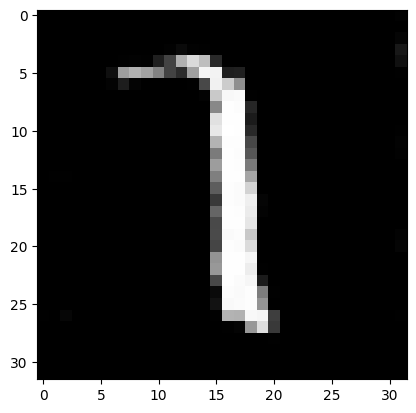

In [15]:
model_path = os.path.join(BINARIES_PATH, 'VANILLA_000000.pth')
# Creates path to the saved trained generator model

assert os.path.exists(model_path), f'Could not find the model {model_path}. You first need to train your generator.'
# Checks if the model file exists before loading

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Uses GPU if available, otherwise CPU


model_state = torch.load(model_path)
# Loads the saved model file

print(f'Model states contains this data: {model_state.keys()}')
# Prints keys stored in the model file

gan_type = model_state["gan_type"]
# Retrieves the GAN type stored in the model

print(f'Using {gan_type} GAN!')
# Displays which GAN type is being used


generator = GeneratorNet().to(device)
# Creates a generator network and moves it to device

generator.load_state_dict(model_state["state_dict"], strict=True)
# Loads trained weights into the generator

generator.eval()
# Sets generator to evaluation mode


generated_imgs_path = os.path.join(DATA_DIR_PATH, 'generated_imagery')
# Path where generated images will be saved

os.makedirs(generated_imgs_path, exist_ok=True)
# Creates folder if it doesn't exist


print('Generating new MNIST-like images!')
# Prints message indicating generation start

generated_img = generate_from_random_latent_vector(generator)
# Generates a new image using random latent vector

save_and_maybe_display_image(generated_imgs_path, generated_img, should_display=True)
# Saves generated image and optionally displays it